# Lab 2 for EC3318/MN3101 Corporate Finance

## Modern Portfolio Theory with PyPortfolioOpt


## 1. Setup and data recap


### Introduction to Modern Portfolio Theory

**Modern Portfolio Theory (MPT)**, developed by Harry Markowitz in 1952, revolutionized investment management by providing a mathematical framework for constructing portfolios that optimize the trade-off between expected return and risk (measured as variance). The key insight is that portfolio risk depends not just on individual asset volatilities, but critically on the **correlations** between assets—enabling diversification benefits.

In this lab, you will:

1. Load and prepare historical stock return data
2. Estimate key inputs (expected returns and covariance matrix) for portfolio optimization
3. Apply mean-variance optimization to find **efficient portfolios**
4. Understand the **efficient frontier** and the **tangency portfolio** (maximum Sharpe ratio)
5. Explore how constraints (e.g., no short-selling) affect optimal portfolios
6. Translate optimal weights into an illustrative whole-share allocation

We'll use **PyPortfolioOpt**, a Python library that implements these concepts with robust numerical optimization methods.


In [3]:
# Import core data manipulation libraries
import pandas as pd  # For working with tabular data (DataFrames)
import numpy as np  # For numerical operations and array computations

# Import PyPortfolioOpt components for portfolio optimization
from pypfopt import (
    EfficientFrontier,  # Main class for mean-variance optimization
    risk_models,  # Functions to estimate covariance matrices
    expected_returns,  # Functions to estimate expected returns
)

# Import discrete allocation tools to convert weights to actual share counts
from pypfopt.discrete_allocation import DiscreteAllocation, get_latest_prices

# Import convex optimization library (used internally by PyPortfolioOpt)
import cvxpy as cp

# Import visualization library (ggplot-style grammar of graphics for Python)
from plotnine import *
from plotnine import options as p9_options
from mizani.formatters import percent_format  # Format axis labels as percentages

# Set default figure size for all plots
p9_options.figure_size = (8, 6)

# Configure pandas display options to show full outputs without truncation
pd.set_option("display.max_rows", None)  # Show all rows in output
pd.set_option("display.max_columns", None)  # Show all columns in output
pd.set_option("display.width", None)  # Auto-detect terminal width
pd.set_option("display.max_colwidth", None)  # Show full column content

### Loading and preparing return data

We keep the historical Excel dataset from Lab 1. Prices are monthly adjusted closing prices. We calculate returns once, without filling missing prices, then retain dates with a return for **every stock**. All Lab 2 summaries, plots and optimisation inputs use these same observations. The original price table remains available for the final historical allocation example.

In [4]:
# Keep the original monthly prices, including the first price observation.
prices_raw = pd.read_excel(
    "downloading_stock_prices.xlsx", sheet_name="Data download", skiprows=7
)
prices_raw["date"] = pd.to_datetime(
    prices_raw["date"], unit="D", origin="1899-12-30"
)
prices_wide = prices_raw.set_index("date").sort_index().sort_index(axis=1)

# Calculate each monthly return once; use a common sample across all stocks.
returns_wide = prices_wide.pct_change(fill_method=None).dropna(how="any")
returns = (
    returns_wide.reset_index()
    .melt(id_vars="date", var_name="symbol", value_name="ret")
    .sort_values(["symbol", "date"])
    .reset_index(drop=True)
)
print(f"Common sample: {len(returns_wide)} monthly returns, "
      f"{returns_wide.index.min():%Y-%m} to {returns_wide.index.max():%Y-%m}")
returns.head()

Common sample: 120 monthly returns, 2014-11 to 2024-10


,date,symbol,ret
0,2014-11-01,AAPL,0.101204
1,2014-12-01,AAPL,-0.071891
2,2015-01-01,AAPL,0.061424
3,2015-02-01,AAPL,0.096449
4,2015-03-01,AAPL,-0.031372


### Summary Statistics by Stock

Before optimization, it's crucial to understand the characteristics of each asset. We compute **descriptive statistics** for the return distribution of each stock:

- **Count**: Number of monthly observations
- **Mean**: Average return (a simple estimate of expected return)
- **Std**: Standard deviation (volatility/risk)
- **Min/Max**: Range of observed returns

These statistics reveal which assets have historically delivered higher returns and which are more volatile. Note that past performance doesn't guarantee future results—one of the key challenges in portfolio optimization!


In [5]:
# Keep full precision for calculations; round only the displayed table.
summary_stats = (
    returns.groupby("symbol")["ret"]
    .agg(["count", "mean", "std", "min", "max"])
    .reset_index()
)
summary_stats.round(3)

,symbol,count,mean,std,min,max
0,AAPL,120,0.021,0.080,-0.184,0.214
1,AMZN,120,0.025,0.089,-0.238,0.271
2,BA,120,0.008,0.112,-0.458,0.459
3,KO,120,0.005,0.046,-0.173,0.129
4,MSFT,120,0.020,0.063,-0.130,0.196
5,PEP,120,0.005,0.043,-0.094,0.112
6,TSLA,120,0.037,0.177,-0.367,0.741
7,WMT,120,0.011,0.054,-0.159,0.148


## 3. Estimating inputs for Markowitz optimization


### Annualised inputs

We use **arithmetic annualised expected returns** throughout: $\mu=12\bar r$, where $\bar r$ is the sample mean monthly return. Annualised covariance is $\Sigma=12\Sigma_{\text{monthly}}$, so volatility is $\sqrt{12}s$.

These are reporting conventions for mean–variance analysis, not realised compounded annual returns. Monthly simple returns compound across time. Covariance scaling assumes stable second moments and no serial covariance; it approximates compounded annual simple-return risk.

Every Sharpe ratio uses an **illustrative annual risk-free rate of 2%**. It is an assumption for this exercise, not a current market quote.

In [6]:
annualisation_factor = 12  # Monthly observations
risk_free_rate = 0.02  # Illustrative annual risk-free rate, used throughout

### Visualising the risk–return trade-off

Each stock is positioned by its annualised volatility (horizontal axis) and arithmetic annualised mean return (vertical axis). Higher return and lower risk are desirable, but combining stocks depends on their covariances too. Diversification can reduce risk at a given expected return; it does not make every portfolio superior to every individual stock.

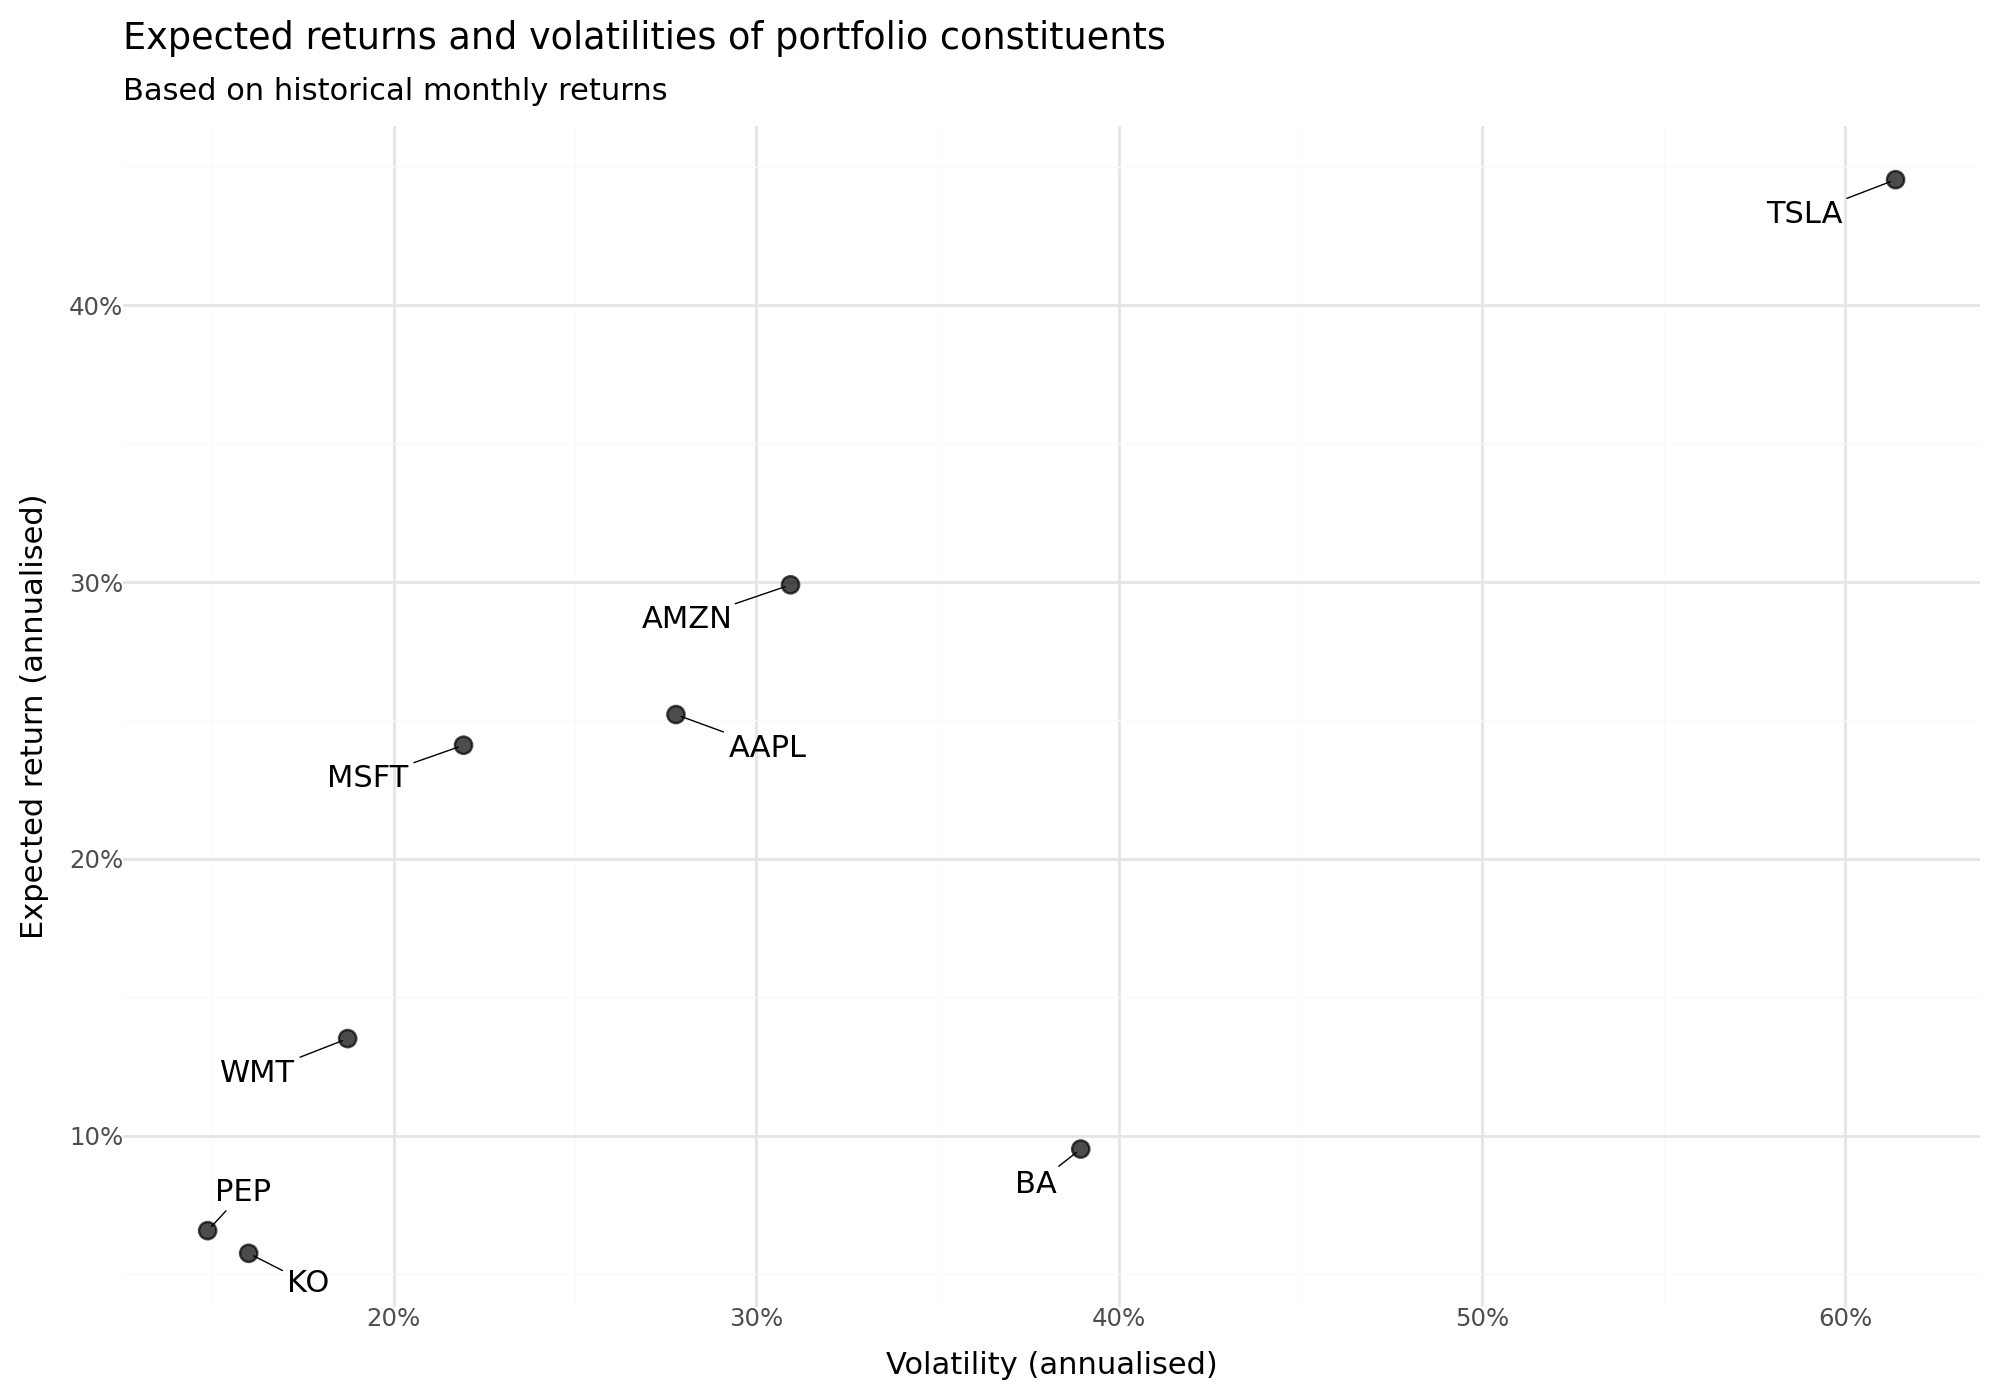

In [7]:
# Create asset summary with expected returns and volatilities
asset_summary = pd.DataFrame(
    {
        "symbol": summary_stats["symbol"],  # Stock ticker symbols
        "mu": summary_stats["mean"] * annualisation_factor,  # Arithmetic annualised mean
        "sigma": summary_stats["std"]
        * np.sqrt(annualisation_factor),  # Annualized volatility
    }
).reset_index(drop=True)

# Create enhanced scatter plot with better text positioning
assets_figure = (
    # Initialize plot with data and aesthetic mappings
    ggplot(asset_summary, aes(x="sigma", y="mu", label="symbol"))
    # Add points for each asset
    + geom_point(size=3, alpha=0.7)
    # Add text labels with automatic adjustment to prevent overlap
    + geom_text(adjust_text={"arrowprops": {"arrowstyle": "-"}})
    # Format x-axis as percentages
    + scale_x_continuous(labels=percent_format())
    # Format y-axis as percentages
    + scale_y_continuous(labels=percent_format())
    # Add informative labels
    + labs(
        x="Volatility (annualised)",
        y="Expected return (annualised)",
        title="Expected returns and volatilities of portfolio constituents",
        subtitle="Based on historical monthly returns",
    )
    # Use clean, professional theme
    + theme_minimal()
    # Set custom figure size
    + theme(figure_size=(10, 7))
)
# Display the plot
assets_figure

### Estimating expected returns

We estimate expected returns using the historical arithmetic mean, annualised by multiplying by 12. In `mean_historical_return()`, **`returns_data=True`** uses our already calculated returns and **`compounding=False`** selects the arithmetic mean. The default instead calculates a geometric estimate.

Historical means are noisy estimates, not reliable forecasts. This exercise shows how an optimiser uses the supplied inputs; it does not establish that the chosen portfolio will perform best in the future.

In [11]:
# Use the same monthly observations as the summary and scatter plot.
mu = expected_returns.mean_historical_return(
    returns_wide, returns_data=True, compounding=False,
    frequency=annualisation_factor,
)
pd.DataFrame({"expected_return": mu}).T

,AAPL,AMZN,BA,KO,MSFT,PEP,TSLA,WMT
expected_return,0.252139,0.299009,0.095152,0.057479,0.241062,0.065666,0.445397,0.135065


### Estimating the Covariance Matrix

The **covariance matrix** is the heart of portfolio optimization. It captures:

- **Variances** (diagonal elements): How volatile each asset is
- **Covariances** (off-diagonal elements): How assets move together

**Why it matters:**

- **Positive covariance**: Assets tend to move in the same direction (less diversification benefit)
- **Negative covariance**: Assets move in opposite directions (strong diversification benefit)
- **Zero covariance**: No linear co-movement; this does not imply independence

The `sample_cov()` function computes the sample covariance matrix from historical returns and annualizes it. This matrix is:

- **Symmetric**: $\Sigma_{ij} = \Sigma_{ji}$
- **Positive semidefinite**: All eigenvalues are non-negative (required for optimization)

**Estimation challenges:**

- For $N$ assets, we must estimate $N(N+1)/2$ parameters
- With limited data, estimation error can be substantial
- Advanced methods (shrinkage, factor models) can improve estimates

In [9]:
# Calculate the sample covariance matrix (annualized)
# This captures both individual asset volatilities and co-movements between assets
cov_matrix = risk_models.sample_cov(
    returns_wide, returns_data=True, frequency=annualisation_factor
)
# Display the covariance matrix
cov_matrix

,AAPL,AMZN,BA,KO,MSFT,PEP,TSLA,WMT
AAPL,0.077177,0.046934,0.034334,0.013812,0.035534,0.015004,0.089604,0.016456
AMZN,0.046934,0.095717,0.032435,0.006558,0.041492,0.009591,0.080279,0.011021
BA,0.034334,0.032435,0.151614,0.022866,0.025333,0.020110,0.044232,0.008749
KO,0.013812,0.006558,0.022866,0.025613,0.012752,0.017558,0.014476,0.011197
MSFT,0.035534,0.041492,0.025333,0.012752,0.048074,0.012168,0.049795,0.010329
PEP,0.015004,0.009591,0.020110,0.017558,0.012168,0.022121,0.017395,0.010440
TSLA,0.089604,0.080279,0.044232,0.014476,0.049795,0.017395,0.376958,0.020390
WMT,0.016456,0.011021,0.008749,0.011197,0.010329,0.010440,0.020390,0.035090


## 4. Mean–variance optimization theory

Let's build some intuition starting with a simple **two-asset** portfolio, then see how the same ideas scale up using **matrix notation** for many assets.

### Two risky assets

Consider two assets, **A** and **B**.

- Expected returns: $\mu_A, \mu_B$
- Standard deviations: $\sigma_A, \sigma_B$
- Correlation: $\rho_{AB}$
- Portfolio weight in A: $w$ (so weight in B is $1-w$)

#### Portfolio expected return

$$\mu_p = w\,\mu_A + (1-w)\,\mu_B$$

#### Portfolio risk (variance)

$$\sigma_p^2 = w^2\sigma_A^2 + (1-w)^2\sigma_B^2 + 2w(1-w)\rho_{AB}\sigma_A\sigma_B$$

- If $\rho_{AB}=1$: a long-only mix has no volatility reduction relative to the weighted average of the two volatilities.
- If $\rho_{AB}<1$: an interior long-only mix has lower volatility than that weighted average; it need not be less volatile than the safer asset.
- If $\rho_{AB}=-1$: perfect negative correlation can theoretically eliminate risk entirely.

#### The opportunity set and the minimum-variance portfolio (MVP)

As $w$ varies from 0 to 1, the point $(\sigma_p,\mu_p)$ traces out a curve called the **two-asset opportunity set**.  
The **MVP** sits at the leftmost point (lowest volatility) on this curve. Its weight on A is:
$$w_A^{\text{mvp}} = \frac{\sigma_B^2 - \rho_{AB}\sigma_A\sigma_B}{\sigma_A^2 + \sigma_B^2 - 2\rho_{AB}\sigma_A\sigma_B}, \quad w_B^{\text{mvp}} = 1 - w_A^{\text{mvp}}$$

> If short-selling is **forbidden**, we clip weights to $[0,1]$ and pick the lowest-variance feasible point.

#### Hitting a target return with two assets

With only two assets, distinct expected returns and full investment, the weight that achieves target return $\mu_p$ is:
$$w = \frac{\mu_p - \mu_B}{\mu_A - \mu_B}, \quad 1-w = \frac{\mu_A - \mu_p}{\mu_A - \mu_B}$$
This is the unique fully invested portfolio reaching that exact return, provided its weights satisfy any bounds.

#### Adding a risk-free asset

Let the risk-free rate be $r_f$ (2% annually in this exercise). Pick any risky portfolio $R$ (a mix of A and B) and combine it with $r_f$ to get a straight **Capital Allocation Line (CAL)** with slope (Sharpe ratio):
$$\text{Sharpe}(R) = \frac{\mu_R - r_f}{\sigma_R}$$
The **tangency portfolio** $R^\ast$ (a particular mix of A and B) maximizes this slope.

### From 2 assets to many (matrix view)

Matrix notation simply extends the same concepts to $N$ assets in a compact form.

- **Weights:** $\boldsymbol{\omega}\in\mathbb{R}^N$ with $\boldsymbol{\omega}^\top \mathbf{1}=1$
- **Expected returns:** $\boldsymbol{\mu}\in\mathbb{R}^N$
- **Covariance matrix:** $\Sigma\in\mathbb{R}^{N\times N}$ (symmetric, positive semidefinite)
- **Ones vector:** $\mathbf{1}\in\mathbb{R}^N$

#### Portfolio return and variance

$$\mu_p = \boldsymbol{\omega}^\top \boldsymbol{\mu}, \quad \sigma_p^2 = \boldsymbol{\omega}^\top \Sigma \boldsymbol{\omega}$$

#### Minimum-variance portfolio (MVP)

$$\boldsymbol{\omega}_{\text{mvp}} = \frac{\Sigma^{-1}\mathbf{1}}{\mathbf{1}^\top \Sigma^{-1}\mathbf{1}}$$

#### Tangency portfolio (with risk-free rate $r_f$)

$$\boldsymbol{\omega}_{\text{tan}} = \frac{\Sigma^{-1}\big(\boldsymbol{\mu}-r_f\mathbf{1}\big)}{\mathbf{1}^\top \Sigma^{-1}\big(\boldsymbol{\mu}-r_f\mathbf{1}\big)}$$

These closed forms require an invertible covariance matrix and unrestricted risky-asset weights. The tangency expression describes the maximum-Sharpe solution when its normalising denominator is positive. Weight bounds can change both solutions; below we solve the bounded problems numerically. Points on its CAL combine the tangency portfolio with the risk-free asset, subject to borrowing and lending permissions.

#### General (target-return) problem

$$\min_{\boldsymbol{\omega}}\;\boldsymbol{\omega}^\top\Sigma\,\boldsymbol{\omega} \quad \text{subject to} \quad \boldsymbol{\omega}^\top\boldsymbol{\mu}=\mu_p, \; \boldsymbol{\omega}^\top\mathbf{1}=1$$
This has a closed-form solution (via Lagrange multipliers) and is computationally fast even for large $N$.

### Key takeaways

- The two-asset case builds intuition: returns combine linearly, risk is curved, and there's a closed-form MVP.
- With a risk-free asset, the **tangency portfolio** is the optimal risky mix; you then scale it up or down based on your risk appetite.
- Matrix notation is just a compact, scalable way to express these same ideas for many assets.

## 5. The efficient frontier and tangency portfolio


### The efficient frontier and tangency portfolio

The efficient frontier contains portfolios for which no feasible portfolio has at least as much expected return and no more risk, with one strict improvement. It is the upper branch of the minimum-variance opportunity set, starting at the global minimum-variance portfolio.

The **tangency portfolio** maximises the Sharpe ratio, $(\mu_p-r_f)/\sigma_p$, over the permitted risky portfolios. Under mean–variance preferences, common inputs and a common borrowing/lending rate, investors can combine this risky portfolio with a risk-free asset. Practical constraints can limit that result.

We first solve **long-only** examples (`weight_bounds=(0, 1)`). We use the textbook objectives without extra penalties and an illustrative annual risk-free rate of 2%.

In [12]:
# Create efficient frontier object and compute portfolios
# Initialize with expected returns (mu) and covariance matrix
ef_sharpe = EfficientFrontier(mu, cov_matrix)

# Maximum Sharpe ratio portfolio (tangency portfolio)
# This solves: max (mu_p - r_f) / sigma_p with the illustrative annual r_f = 2%
max_sharpe_weights = ef_sharpe.max_sharpe(risk_free_rate=risk_free_rate)
# Clean weights: remove tiny positions (below threshold) for practical implementation
cleaned_max_sharpe = ef_sharpe.clean_weights()
# Calculate portfolio performance metrics (expected return, volatility, Sharpe ratio)
max_sharpe_perf = ef_sharpe.portfolio_performance(verbose=True, risk_free_rate=risk_free_rate)

print("\n" + "=" * 50)
print("MAXIMUM SHARPE RATIO PORTFOLIO")
print("=" * 50)
# Convert weights dictionary to DataFrame and sort by weight size
max_sharpe_weights_df = (
    pd.Series(cleaned_max_sharpe, name="weight").sort_values(ascending=False).to_frame()
)
# Create metrics series for cleaner display
max_sharpe_metrics = pd.Series(
    max_sharpe_perf,
    index=["expected_return", "volatility", "sharpe_ratio"],
    name="max_sharpe_portfolio",
)
print("Portfolio weights:")
print(max_sharpe_weights_df)
print(f"\nPerformance metrics:")
print(max_sharpe_metrics)

Expected annual return: 23.4%
Annual volatility: 18.5%
Sharpe Ratio: 1.15

MAXIMUM SHARPE RATIO PORTFOLIO
Portfolio weights:
       weight
MSFT  0.42716
WMT   0.28838
AMZN  0.17581
TSLA  0.06047
AAPL  0.04818
BA    0.00000
KO    0.00000
PEP   0.00000

Performance metrics:
expected_return    0.233572
volatility         0.185278
sharpe_ratio       1.152710
Name: max_sharpe_portfolio, dtype: float64


### Minimum volatility portfolio (MVP)

The MVP has the lowest variance in the specified feasible set and lies at the leftmost point of its frontier. It does not use expected returns to choose its weights, though we still report the return estimated for those weights.

Here the optimisation minimises $\boldsymbol{\omega}^\top\Sigma\boldsymbol{\omega}$ subject to weights summing to one and each weight lying between zero and one. Minimum variance does not guarantee a highly diversified portfolio or good future performance: the answer depends on the estimated covariance matrix.

In [13]:
# Minimum volatility portfolio
# Create a fresh EfficientFrontier object (each optimization needs its own instance)
ef_min_vol = EfficientFrontier(mu, cov_matrix)
# Optimize for minimum volatility (ignores expected returns)
min_vol_weights = ef_min_vol.min_volatility()
# Clean up small weights for practical implementation
cleaned_min_vol = ef_min_vol.clean_weights()
# Calculate performance metrics
min_vol_perf = ef_min_vol.portfolio_performance(verbose=True, risk_free_rate=risk_free_rate)

print("\n" + "=" * 50)
print("MINIMUM VOLATILITY PORTFOLIO")
print("=" * 50)
# Convert weights to DataFrame and sort
min_vol_weights_df = (
    pd.Series(cleaned_min_vol, name="weight").sort_values(ascending=False).to_frame()
)
# Create metrics series
min_vol_metrics = pd.Series(
    min_vol_perf,
    index=["expected_return", "volatility", "sharpe_ratio"],
    name="min_vol_portfolio",
)
print("Portfolio weights:")
print(min_vol_weights_df)
print(f"\nPerformance metrics:")
print(min_vol_metrics)

Expected annual return: 10.9%
Annual volatility: 12.9%
Sharpe Ratio: 0.69

MINIMUM VOLATILITY PORTFOLIO
Portfolio weights:
       weight
PEP   0.39545
WMT   0.24645
KO    0.21343
MSFT  0.09331
AMZN  0.05136
AAPL  0.00000
BA    0.00000
TSLA  0.00000

Performance metrics:
expected_return    0.109373
volatility         0.129213
sharpe_ratio       0.691672
Name: min_vol_portfolio, dtype: float64


### Target return portfolio

`efficient_return()` minimises variance while requiring expected return **at least** the target:

$$\min_{\boldsymbol{\omega}}\boldsymbol{\omega}^\top\Sigma\boldsymbol{\omega}\quad\text{subject to}\quad\boldsymbol{\omega}^\top\boldsymbol{\mu}\geq\mu_{\text{target}},\quad\boldsymbol{\omega}^\top\mathbf{1}=1,\quad0\leq\omega_i\leq1.$$

A target above the maximum feasible expected return cannot be met. A target below the MVP's expected return returns the MVP, whose expected return exceeds that target. Above the MVP, the return constraint normally binds.

We use the mean of the asset expected returns: the equal-weight portfolio makes that target feasible.

In [14]:
# Set a target return (clipped to feasible range for safety)
target_return = float(np.clip(mu.mean(), mu.min(), mu.max()))
# Create fresh EfficientFrontier object
ef_target = EfficientFrontier(mu, cov_matrix)
# Optimize to achieve target return with minimum risk
target_weights = ef_target.efficient_return(target_return=target_return)
# Clean weights
cleaned_target = ef_target.clean_weights()
# Calculate performance (verbose=False to suppress output)
target_perf = ef_target.portfolio_performance(verbose=False, risk_free_rate=risk_free_rate)

# Convert to DataFrames for display
target_weights_df = (
    pd.Series(cleaned_target, name="weight").sort_values(ascending=False).to_frame()
)
target_metrics = pd.Series(
    target_perf,
    index=["expected_return", "volatility", "sharpe_ratio"],
    name=f"target_return_{target_return:.2%}",
)
# Display weights and metrics
target_weights_df, target_metrics

(       weight
 MSFT  0.35842
 WMT   0.34469
 AMZN  0.12803
 PEP   0.10815
 AAPL  0.03369
 TSLA  0.02702
 KO    0.00000
 BA    0.00000,
 expected_return    0.198871
 volatility         0.160545
 sharpe_ratio       1.114146
 Name: target_return_19.89%, dtype: float64)

## 6. Comparing bounded short-selling and long-only portfolios

### Short-selling and position limits

A short position has a negative weight: the investor borrows shares, sells them and later buys shares to return to the lender. Shorting can hedge portfolio risk or express a return view, but introduces borrowing costs, collateral requirements and potentially large losses.

Compare two fully invested sets (weights sum to one):

1. **Bounded short-selling:** `weight_bounds=(-1, 1)` permits −100% to +100% in each stock. This is **not unrestricted optimisation**; individual position limits still apply and gross exposure can exceed 100%.
2. **Long-only:** `weight_bounds=(0, 1)` prohibits negative weights.

Expanding the feasible set cannot worsen the optimum of the same in-sample objective. It need not improve it strictly and does not guarantee better future performance. This example excludes shorting costs.

In [15]:
print("=" * 60)
print("COMPARING BOUNDED SHORT-SELLING VS. LONG-ONLY PORTFOLIOS")
print("=" * 60)

# =============================================================================
# BOUNDED SHORT-SELLING PORTFOLIOS (Allow short-selling)
# =============================================================================
print("\n" + "=" * 60)
print("BOUNDED SHORT-SELLING PORTFOLIOS (SHORT-SELLING ALLOWED)")
print("=" * 60)

# Maximum Sharpe with short-selling allowed
# weight_bounds=(-1, 1) means: -100% ≤ weight ≤ +100% for each asset
# Negative weights = short positions, Positive weights = long positions
ef_bounded_short_sharpe = EfficientFrontier(mu, cov_matrix, weight_bounds=(-1, 1))
# Optimize for maximum Sharpe ratio
bounded_short_sharpe_weights = ef_bounded_short_sharpe.max_sharpe(risk_free_rate=risk_free_rate)
# Clean weights (removes positions below threshold)
cleaned_bounded_short_sharpe = ef_bounded_short_sharpe.clean_weights()
# Calculate performance metrics
bounded_short_sharpe_perf = ef_bounded_short_sharpe.portfolio_performance(verbose=False, risk_free_rate=risk_free_rate)

print("\nMaximum Sharpe Portfolio (Bounded short-selling):")
bounded_short_sharpe_df = (
    pd.Series(cleaned_bounded_short_sharpe, name="weight")
    .sort_values(ascending=False)
    .to_frame()
)
print("Weights:")
print(bounded_short_sharpe_df)
print(f"\nExpected Return: {bounded_short_sharpe_perf[0]:.4f}")
print(f"Volatility: {bounded_short_sharpe_perf[1]:.4f}")
print(f"Sharpe Ratio: {bounded_short_sharpe_perf[2]:.4f}")

# Count short positions
num_shorts = sum(1 for w in cleaned_bounded_short_sharpe.values() if w < 0)
num_longs = sum(1 for w in cleaned_bounded_short_sharpe.values() if w > 0)
print(f"\nShort positions: {num_shorts} assets")
print(f"Long positions: {num_longs} assets")

# Minimum volatility with short-selling allowed
ef_bounded_short_minvol = EfficientFrontier(mu, cov_matrix, weight_bounds=(-1, 1))
# Optimize for minimum volatility
bounded_short_minvol_weights = ef_bounded_short_minvol.min_volatility()
# Clean weights
cleaned_bounded_short_minvol = ef_bounded_short_minvol.clean_weights()
# Calculate performance
bounded_short_minvol_perf = ef_bounded_short_minvol.portfolio_performance(verbose=False, risk_free_rate=risk_free_rate)

print("\nMinimum Volatility Portfolio (Bounded short-selling):")
bounded_short_minvol_df = (
    pd.Series(cleaned_bounded_short_minvol, name="weight")
    .sort_values(ascending=False)
    .to_frame()
)
print("Weights:")
print(bounded_short_minvol_df)
print(f"\nExpected Return: {bounded_short_minvol_perf[0]:.4f}")
print(f"Volatility: {bounded_short_minvol_perf[1]:.4f}")
print(f"Sharpe Ratio: {bounded_short_minvol_perf[2]:.4f}")

# Count short positions
num_shorts_mv = sum(1 for w in cleaned_bounded_short_minvol.values() if w < 0)
num_longs_mv = sum(1 for w in cleaned_bounded_short_minvol.values() if w > 0)
print(f"\nShort positions: {num_shorts_mv} assets")
print(f"Long positions: {num_longs_mv} assets")

# =============================================================================
# LONG-ONLY PORTFOLIOS (No short-selling)
# =============================================================================
print("\n" + "=" * 60)
print("LONG-ONLY PORTFOLIOS (NO SHORT-SELLING)")
print("=" * 60)

# Maximum Sharpe with long-only constraint
# weight_bounds=(0, 1) means: 0 ≤ weight ≤ 1 for each asset (no shorts, no leverage)
ef_long_only = EfficientFrontier(mu, cov_matrix, weight_bounds=(0, 1))
# Optimize for maximum Sharpe ratio
long_only_sharpe_weights = ef_long_only.max_sharpe(risk_free_rate=risk_free_rate)
# Clean weights (removes positions below threshold)
cleaned_long_only_sharpe = ef_long_only.clean_weights()
# Calculate performance metrics
long_only_sharpe_perf = ef_long_only.portfolio_performance(verbose=False, risk_free_rate=risk_free_rate)

print("\nMaximum Sharpe Portfolio (Long-only):")
long_only_sharpe_df = (
    pd.Series(cleaned_long_only_sharpe, name="weight")
    .sort_values(ascending=False)
    .to_frame()
)
print("Weights:")
print(long_only_sharpe_df)
print(f"\nExpected Return: {long_only_sharpe_perf[0]:.4f}")
print(f"Volatility: {long_only_sharpe_perf[1]:.4f}")
print(f"Sharpe Ratio: {long_only_sharpe_perf[2]:.4f}")

# Minimum volatility with long-only constraint
ef_long_only_minvol = EfficientFrontier(mu, cov_matrix, weight_bounds=(0, 1))
# Optimize for minimum volatility
long_only_minvol_weights = ef_long_only_minvol.min_volatility()
# Clean weights
cleaned_long_only_minvol = ef_long_only_minvol.clean_weights()
# Calculate performance
long_only_minvol_perf = ef_long_only_minvol.portfolio_performance(verbose=False, risk_free_rate=risk_free_rate)

print("\nMinimum Volatility Portfolio (Long-only):")
long_only_minvol_df = (
    pd.Series(cleaned_long_only_minvol, name="weight")
    .sort_values(ascending=False)
    .to_frame()
)
print("Weights:")
print(long_only_minvol_df)
print(f"\nExpected Return: {long_only_minvol_perf[0]:.4f}")
print(f"Volatility: {long_only_minvol_perf[1]:.4f}")
print(f"Sharpe Ratio: {long_only_minvol_perf[2]:.4f}")

# =============================================================================
# COMPARISON: Cost of constraints
# =============================================================================
print("\n" + "=" * 60)
print("IMPACT OF SHORT-SELLING CONSTRAINT")
print("=" * 60)

print("\nMaximum Sharpe Portfolio:")
print(
    f"  Bounded short-selling - Sharpe: {bounded_short_sharpe_perf[2]:.4f}, Vol: {bounded_short_sharpe_perf[1]:.4f}"
)
print(
    f"  Long-only     - Sharpe: {long_only_sharpe_perf[2]:.4f}, Vol: {long_only_sharpe_perf[1]:.4f}"
)
sharpe_loss = (
    (bounded_short_sharpe_perf[2] - long_only_sharpe_perf[2])
    / bounded_short_sharpe_perf[2]
) * 100
print(f"  → Sharpe ratio reduction: {sharpe_loss:.1f}%")

print("\nMinimum Volatility Portfolio:")
print(
    f"  Bounded short-selling - Vol: {bounded_short_minvol_perf[1]:.4f}, Return: {bounded_short_minvol_perf[0]:.4f}"
)
print(
    f"  Long-only     - Vol: {long_only_minvol_perf[1]:.4f}, Return: {long_only_minvol_perf[0]:.4f}"
)
vol_increase = (
    (long_only_minvol_perf[1] - bounded_short_minvol_perf[1])
    / bounded_short_minvol_perf[1]
) * 100
print(f"  → Volatility increase: {vol_increase:.1f}%")

COMPARING BOUNDED SHORT-SELLING VS. LONG-ONLY PORTFOLIOS

BOUNDED SHORT-SELLING PORTFOLIOS (SHORT-SELLING ALLOWED)

Maximum Sharpe Portfolio (Bounded short-selling):
Weights:
       weight
MSFT  0.60022
WMT   0.42296
AMZN  0.19137
AAPL  0.10449
TSLA  0.07126
BA   -0.06789
PEP  -0.11461
KO   -0.20779

Expected Return: 0.2912
Volatility: 0.2288
Sharpe Ratio: 1.1854

Short positions: 3 assets
Long positions: 5 assets

Minimum Volatility Portfolio (Bounded short-selling):
Weights:
       weight
PEP   0.40520
WMT   0.24943
KO    0.22023
MSFT  0.11140
AMZN  0.07288
BA   -0.01580
TSLA -0.01971
AAPL -0.02361

Expected Return: 0.1054
Volatility: 0.1283
Sharpe Ratio: 0.6651

Short positions: 3 assets
Long positions: 5 assets

LONG-ONLY PORTFOLIOS (NO SHORT-SELLING)

Maximum Sharpe Portfolio (Long-only):
Weights:
       weight
MSFT  0.42716
WMT   0.28838
AMZN  0.17581
TSLA  0.06047
AAPL  0.04818
BA    0.00000
KO    0.00000
PEP   0.00000

Expected Return: 0.2336
Volatility: 0.1853
Sharpe Ratio: 1.

### Interpreting the comparison

Negative weights identify short positions. The optimiser chooses them from the complete set of expected returns and covariances; a short weight alone does not establish negative alpha or overvaluation.

The bounded short-selling set contains the long-only set. It can therefore attain a Sharpe ratio at least as high and minimum variance at least as low, up to solver tolerances. If the added flexibility is unused, results coincide.

These comparisons use historical estimates and omit trading and borrowing costs. They are not guarantees about future returns or a recommendation to short stocks.

## 7. Visualizing the efficient frontier


### Plotting each efficient frontier

For each set of weight bounds, we first find its global minimum-variance portfolio and maximum feasible expected return. We solve minimum-variance portfolios on a return grid between those two endpoints. This traces the efficient upper branch and includes the extra return range that short-selling may permit.

The bounded short-selling frontier can have no more minimum risk than the long-only frontier **at a common return target**. The two may coincide. We let numerical failures surface so an incomplete plot is not mistaken for a complete frontier.

In [17]:
def compute_frontier_points(mu_vec, cov, weight_bounds):
    """Trace the efficient upper branch under the specified position bounds."""
    minimum = EfficientFrontier(mu_vec, cov, weight_bounds=weight_bounds)
    minimum.min_volatility()
    minimum_return = minimum.portfolio_performance(
        risk_free_rate=risk_free_rate
    )[0]

    # Maximise a linear expected return subject to the same position bounds.
    weights = cp.Variable(len(mu_vec))
    maximum = cp.Problem(cp.Maximize(mu_vec.to_numpy() @ weights), [
        cp.sum(weights) == 1,
        weights >= weight_bounds[0], weights <= weight_bounds[1],
    ])
    maximum.solve()
    if maximum.status != cp.OPTIMAL:
        raise RuntimeError(f"Maximum-return calculation failed: {maximum.status}")
    # A tiny margin avoids solver rounding at the exact upper endpoint.
    targets = np.linspace(minimum_return, float(maximum.value) - 1e-7, 50)
    rows = []
    for target in targets:
        ef = EfficientFrontier(mu_vec, cov, weight_bounds=weight_bounds)
        ef.efficient_return(float(target))
        perf = ef.portfolio_performance(risk_free_rate=risk_free_rate)
        rows.append({"target_return": target, "expected_return": perf[0],
                     "volatility": perf[1], "sharpe_ratio": perf[2]})
    return pd.DataFrame(rows)


frontier_bounded_short = compute_frontier_points(mu, cov_matrix, (-1, 1))
frontier_long_only = compute_frontier_points(mu, cov_matrix, (0, 1))
frontier_bounded_short["constraint_type"] = "Bounded short-selling"
frontier_long_only["constraint_type"] = "Long-only"
all_frontiers = pd.concat([frontier_bounded_short, frontier_long_only], ignore_index=True)

# Individual asset positions (for reference on plot)
asset_positions = pd.DataFrame(
    {
        "symbol": mu.index,
        "expected_return": mu,
        "volatility": np.sqrt(np.diag(cov_matrix)),  # Square root of variance
    }
).reset_index(drop=True)

# Key portfolios with different constraints (for annotation on plot)
key_portfolios = pd.DataFrame(
    [
        {
            "portfolio": "Min vol (short)",
            "expected_return": bounded_short_minvol_perf[0],
            "volatility": bounded_short_minvol_perf[1],
            "constraint_type": "Bounded short-selling",
        },
        {
            "portfolio": "Max Sharpe (short)",
            "expected_return": bounded_short_sharpe_perf[0],
            "volatility": bounded_short_sharpe_perf[1],
            "constraint_type": "Bounded short-selling",
        },
        {
            "portfolio": "Target (Long-only)",
            "expected_return": target_perf[0],
            "volatility": target_perf[1],
            "constraint_type": "Long-only",
        },
        {
            "portfolio": "Min Vol (Long-only)",
            "expected_return": long_only_minvol_perf[0],
            "volatility": long_only_minvol_perf[1],
            "constraint_type": "Long-only",
        },
        {
            "portfolio": "Max Sharpe (Long-only)",
            "expected_return": long_only_sharpe_perf[0],
            "volatility": long_only_sharpe_perf[1],
            "constraint_type": "Long-only",
        },
    ]
).reset_index(drop=True)

### Reading the frontier plot

- Blue represents bounded short-selling; orange represents long-only portfolios.
- The leftmost point of each curve is its global minimum-variance portfolio.
- The tangency portfolio has the greatest slope from the point (zero volatility, 2% return), not necessarily the highest return on the plot.
- Grey points show individual stocks. Compare an asset with frontier portfolios at the same return or risk: **not every frontier portfolio dominates every asset**.
- The target-return portfolio is long-only, matching the optimisation above. Curves can overlap when both constraints yield the same solution.

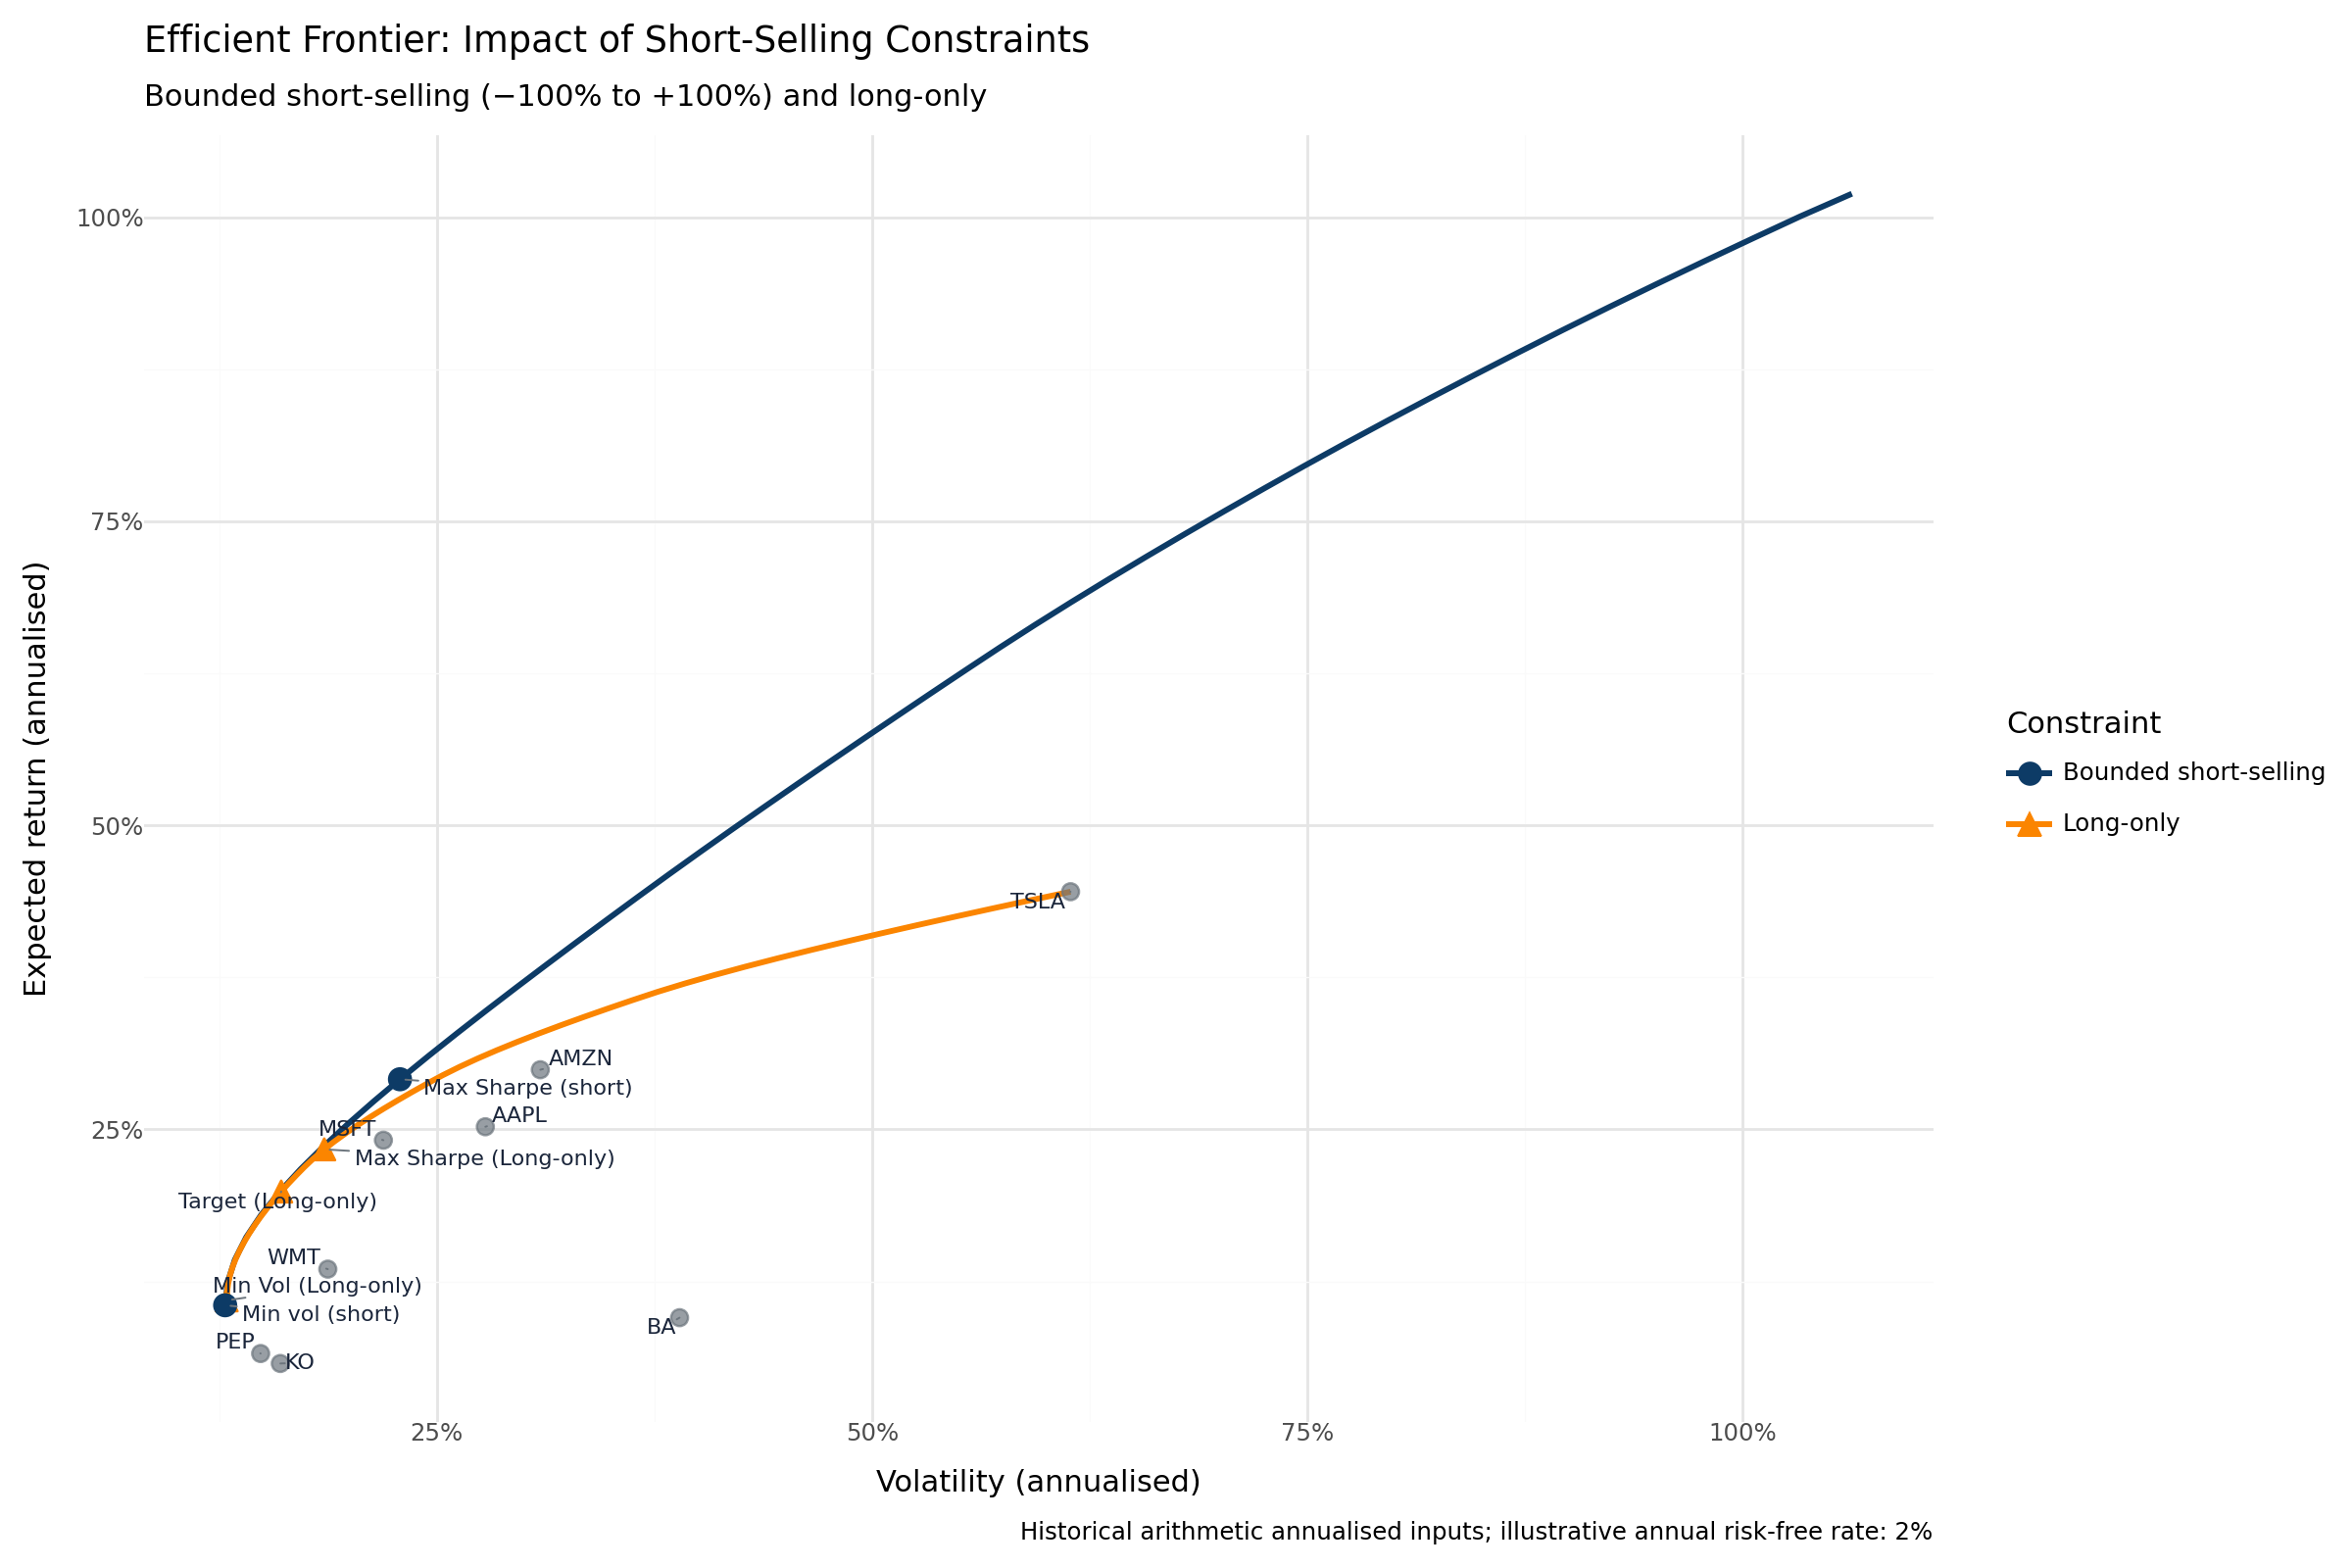

In [18]:
# Adjust all labels together so asset and portfolio labels avoid each other.
plot_labels = pd.concat([
    asset_positions.rename(columns={"symbol": "label"}),
    key_portfolios.rename(columns={"portfolio": "label"}),
], ignore_index=True)
np.random.seed(3318)  # Reproducible initial displacement of overlapping labels

enhanced_plot = (
    ggplot()
    + geom_line(
        all_frontiers,
        aes(x="volatility", y="expected_return", color="constraint_type"),
        size=1.2,
    )
    + geom_point(
        asset_positions, aes(x="volatility", y="expected_return"),
        color="#6c757d", size=3, alpha=0.7,
    )
    + geom_point(
        key_portfolios,
        aes(x="volatility", y="expected_return", color="constraint_type",
            shape="constraint_type"), size=4,
    )
    + geom_text(
        plot_labels, aes(x="volatility", y="expected_return", label="label"),
        size=8, color="#1b263b",
        adjust_text={
            "arrowprops": {"arrowstyle": "-", "color": "#6c757d", "lw": 0.7},
            "expand": (1.3, 1.5), "force_text": (0.6, 0.9),
            "force_static": (0.4, 0.5), "force_pull": (0.005, 0.005),
            "iter_lim": 1000,
        },
    )
    + scale_x_continuous(labels=percent_format())
    + scale_y_continuous(labels=percent_format())
    + scale_color_manual(values={"Bounded short-selling": "#0d3b66", "Long-only": "#fb8500"})
    + scale_shape_manual(values={"Bounded short-selling": "o", "Long-only": "^"})
    + labs(
        title="Efficient Frontier: Impact of Short-Selling Constraints",
        subtitle="Bounded short-selling (−100% to +100%) and long-only",
        x="Volatility (annualised)", y="Expected return (annualised)",
        color="Constraint", shape="Constraint",
        caption="Historical arithmetic annualised inputs; illustrative annual risk-free rate: 2%",
    )
    + theme_minimal()
    + theme(figure_size=(12, 8))
)
enhanced_plot

### Comparing Portfolio Weights Across Strategies

Understanding **how** different strategies allocate capital across assets is crucial for:

1. **Implementation**: Do we need short-selling capability?
2. **Risk management**: Are we overly concentrated in few assets?
3. **Transaction costs**: Extreme weights may be costly to establish
4. **Interpretation**: Why does this portfolio work?

The weight comparison table shows:

- **Positive weights**: Long positions (buy and hold)
- **Negative weights**: Short positions (borrow and sell)
- **Zero weights**: Assets excluded from the portfolio

**What to look for:**

- **Concentration**: Are weights spread across many assets or focused on a few?
- **Short positions**: How important is short-selling to achieving optimal results?
- **Stability**: Do small changes in optimization parameters lead to dramatic weight changes?



PORTFOLIO WEIGHTS COMPARISON
Portfolio weights summary:
      Max Sharpe (Short)  Min Vol (Short)  Max Sharpe (Long)  Min Vol (Long)
AAPL             0.10449         -0.02361            0.04818         0.00000
AMZN             0.19137          0.07288            0.17581         0.05136
BA              -0.06789         -0.01580            0.00000         0.00000
KO              -0.20779          0.22023            0.00000         0.21343
MSFT             0.60022          0.11140            0.42716         0.09331
PEP             -0.11461          0.40520            0.00000         0.39545
TSLA             0.07126         -0.01971            0.06047         0.00000
WMT              0.42296          0.24943            0.28838         0.24645


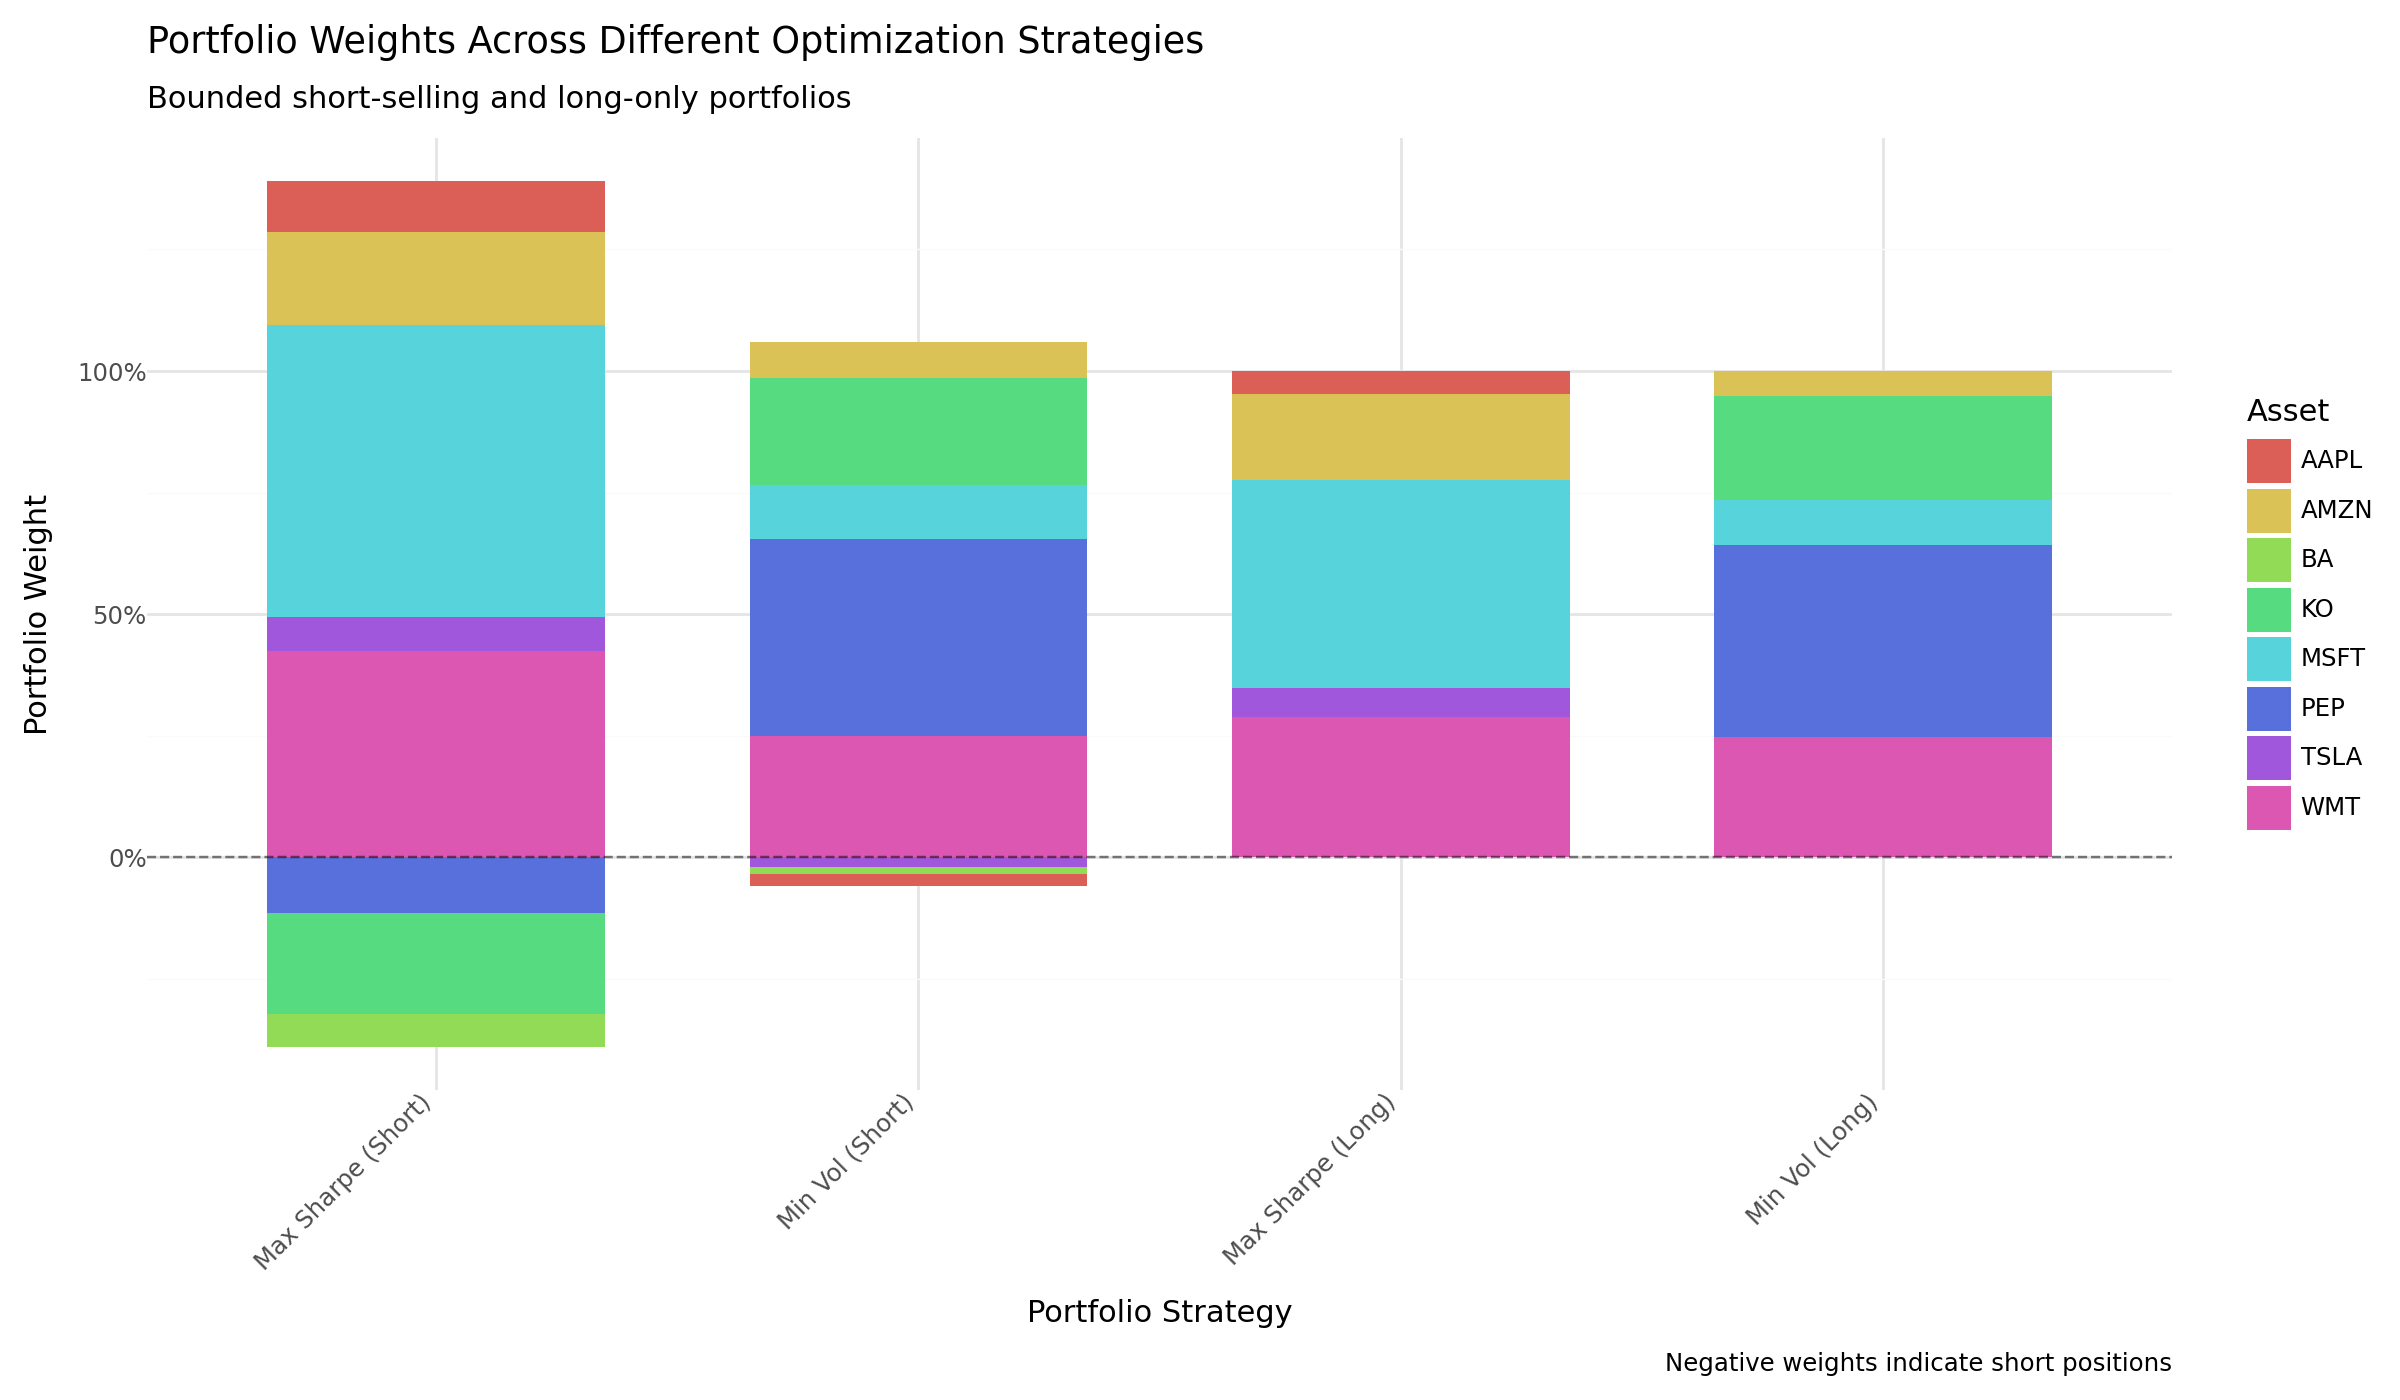

In [19]:
# Portfolio weights comparison visualization
print("\n" + "=" * 50)
print("PORTFOLIO WEIGHTS COMPARISON")
print("=" * 50)

# Compile all portfolio weights (excluding custom constraints for now)
# Each column represents one portfolio strategy
weights_comparison = pd.DataFrame(
    {
        "Max Sharpe (Short)": pd.Series(
            cleaned_bounded_short_sharpe
        ),  # Maximum Sharpe, bounded_short
        "Min Vol (Short)": pd.Series(
            cleaned_bounded_short_minvol
        ),  # Minimum volatility, bounded_short
        "Max Sharpe (Long)": pd.Series(
            cleaned_long_only_sharpe
        ),  # Maximum Sharpe, long-only
        "Min Vol (Long)": pd.Series(
            cleaned_long_only_minvol
        ),  # Minimum volatility, long-only
    }
).fillna(
    0
)  # Replace NaN with 0 (assets not included in portfolio)

print("Portfolio weights summary:")
print(weights_comparison)

# Create stacked bar chart with better styling
# Reshape data from wide to long format for ggplot
weights_long = (
    weights_comparison.reset_index()
    .melt(id_vars="index", var_name="Portfolio", value_name="Weight")
    .rename(columns={"index": "Asset"})
)

# Add constraint type for coloring
weights_long["Constraint_Type"] = weights_long["Portfolio"].apply(
    lambda x: "Long-only" if "Long" in x else "Bounded short-selling"
)

# Sort portfolios for better display (explicit ordering)
weights_long["Portfolio"] = pd.Categorical(
    weights_long["Portfolio"],
    categories=[
        "Max Sharpe (Short)",
        "Min Vol (Short)",
        "Max Sharpe (Long)",
        "Min Vol (Long)",
    ],
    ordered=True,
)

# Create stacked bar chart
weights_plot = (
    ggplot(weights_long, aes(x="Portfolio", y="Weight", fill="Asset"))
    # Stacked bars showing composition of each portfolio
    + geom_col(position="stack", width=0.7)
    # Add horizontal line at zero to clearly show short positions
    + geom_hline(yintercept=0, linetype="dashed", color="black", alpha=0.5)
    # Format y-axis as percentages
    + scale_y_continuous(labels=percent_format())
    # Add comprehensive labels
    + labs(
        title="Portfolio Weights Across Different Optimization Strategies",
        subtitle="Bounded short-selling and long-only portfolios",
        x="Portfolio Strategy",
        y="Portfolio Weight",
        caption="Negative weights indicate short positions",
    )
    # Use minimal theme
    + theme_minimal()
    # Rotate x-axis labels for readability
    + theme(
        axis_text_x=element_text(angle=45, hjust=1),
        figure_size=(12, 7),
        legend_position="right",
    )
    # Customize legend
    + guides(fill=guide_legend(title="Asset"))
)

# Display the plot
weights_plot

## 8. From weights to an illustrative allocation

Optimized weights rarely translate directly into actual trades. PyPortfolioOpt includes a discrete allocator that converts optimal weights into whole-share counts given a budget.


### From continuous weights to whole shares

We assume whole-share trading and a $10,000 budget. Some brokers permit fractional shares; this exercise does not. `DiscreteAllocation.greedy_portfolio()` is a heuristic that approximates the target weights within the budget. It does not guarantee the closest possible allocation or spend every dollar.

We use the last available **historical adjusted prices** from the dataset. These are illustrative units, not current executable prices, so the result is a classroom allocation rather than a live trade recommendation. Trading fees and taxes are omitted.

The output is a dictionary of integer share counts and leftover cash. We check that invested value plus cash equals the budget.

In [ ]:
# Last historical adjusted price for each asset (illustrative, not executable)
latest_prices = get_latest_prices(prices_wide)
# Set portfolio budget (how much capital we have to invest)
portfolio_value = 10_000

print("=" * 60)
print("DISCRETE ALLOCATION FOR LONG-ONLY MAX SHARPE PORTFOLIO")
print("=" * 60)
print("\nIllustrative whole-share allocation at historical adjusted prices.\n")

# Create discrete allocation object with:
# - Target weights (from long-only maximum Sharpe portfolio)
# - Latest prices (to convert $ amounts to share counts)
# - Total budget (portfolio value)
da = DiscreteAllocation(
    cleaned_long_only_sharpe, latest_prices, total_portfolio_value=portfolio_value
)
# Run greedy allocation algorithm to determine share counts
# Returns: (1) dictionary of {symbol: shares}, (2) leftover cash
allocation, leftover_cash = da.greedy_portfolio()

# Display results
print("Share allocation:")
allocation_df = pd.Series(allocation, name="shares").sort_index()
print(allocation_df)
print(f"\nLeftover cash: ${leftover_cash:.2f}")

# Calculate total invested
total_invested = sum(
    allocation[symbol] * latest_prices[symbol] for symbol in allocation
)
print(f"Total invested: ${total_invested:.2f}")
print(f"Portfolio utilization: {(total_invested/portfolio_value)*100:.1f}%")
assert np.isclose(total_invested + leftover_cash, portfolio_value)
assert leftover_cash >= -1e-8

### Why this example uses long-only weights

PyPortfolioOpt can also allocate long/short portfolios, including negative share counts. We use long-only weights to keep the budget example simple. A real short position additionally requires access to borrowed shares, collateral and allowances for borrowing costs; a negative integer alone does not establish that it can be traded.